# Notebook 02: Microstructure Parameter Calibration & Regime Estimation

**Project:** QRD 2027: Liquidity-Adaptive Optimal Execution in Indian Equities  
**Universe:** Top NIFTY 50 Equities (`RELIANCE`, `HDFCBANK`, `TCS`)  
**Objective:** Multi-stock empirical calibration of Average Daily Volume (ADV), 30-minute volume smile curves, rolling realized volatility, volatility regimes, liquidity regimes, and Almgren-Chriss simulation assumptions.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import get_config
from src.calibration import run_calibration_pipeline, generate_calibration_summary, save_calibration_report

config = get_config(reload=True)
print(f'Configuration loaded for project: {config.project.name}')


Configuration loaded for project: qrd2027_adaptive_execution


## 1. Multi-Stock Calibration Execution
Calibrates empirical ADV, volume profiles, and realized volatility distributions across RELIANCE, HDFCBANK, and TCS.


In [2]:
stocks = ['RELIANCE', 'HDFCBANK', 'TCS']
calib_summaries = []

for ticker in stocks:
    proc_path = project_root / 'data' / 'processed' / f'{ticker}_1min.parquet'
    if proc_path.exists():
        df_p = pd.read_parquet(proc_path)
        report = generate_calibration_summary(df_p, ticker=ticker, config=config)
        save_calibration_report(report, output_dir=project_root / 'reports' / 'tables', filename_prefix=f'{ticker}_calibration_report')
        calib_summaries.append({
            'Ticker': ticker,
            'Trading Days': report.total_trading_days,
            'ADV (Shares)': round(report.average_daily_volume, 0),
            'Daily Turnover (Cr INR)': round(report.average_daily_turnover_inr / 1e7, 2),
            'Mean Realized Vol': f'{report.volatility.mean_realised_vol*100:.2f}%',
            'Calm Max (p40)': f'{report.volatility.regime_threshold_calm_max*100:.2f}%',
            'Stressed Min (p80)': f'{report.volatility.regime_threshold_stressed_min*100:.2f}%',
            'Buy-Side Intraday Cost': f'{report.simulation_assumptions.transaction_cost_schedule.get("buy_side_total_bps", 2.4653):.4f} bps'
        })

calib_summary_df = pd.DataFrame(calib_summaries)
print('Multi-Stock Calibration Summary Table:')
calib_summary_df


Multi-Stock Calibration Summary Table:


,Ticker,Trading Days,ADV (Shares),Daily Turnover (Cr INR),Mean Realized Vol,Calm Max (p40),Stressed Min (p80),Buy-Side Intraday Cost
0,RELIANCE,20,825214.0,240.35,17.74%,17.04%,20.11%,2.4653 bps
1,HDFCBANK,20,1012791.0,171.51,18.70%,17.97%,21.20%,2.4653 bps
2,TCS,20,539824.0,206.22,16.04%,15.29%,18.12%,2.4653 bps


## 2. Compare 30-Minute Intraday Volume Smile Curves Across Universe


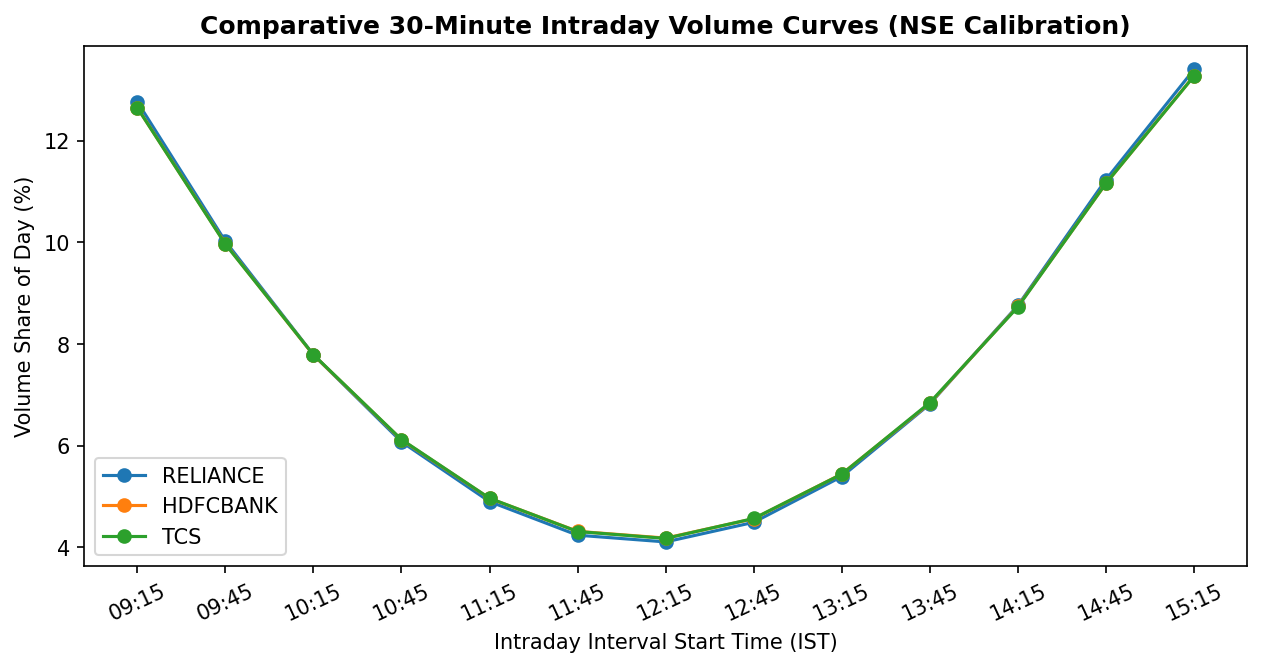

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=150)
labels = ['09:15', '09:45', '10:15', '10:45', '11:15', '11:45', '12:15', '12:45', '13:15', '13:45', '14:15', '14:45', '15:15']

for ticker in stocks:
    proc_path = project_root / 'data' / 'processed' / f'{ticker}_1min.parquet'
    if proc_path.exists():
        df_p = pd.read_parquet(proc_path)
        rep = generate_calibration_summary(df_p, ticker=ticker, config=config)
        curve = [rep.volume_profile.buckets_30m[k] * 100 for k in sorted(rep.volume_profile.buckets_30m.keys())]
        ax.plot(labels, curve, marker='o', linewidth=1.5, label=ticker)

ax.set_title('Comparative 30-Minute Intraday Volume Curves (NSE Calibration)', fontweight='bold')
ax.set_xlabel('Intraday Interval Start Time (IST)')
ax.set_ylabel('Volume Share of Day (%)')
ax.legend(frameon=True)
plt.xticks(rotation=25)
plt.show()
